# CNN-Based Handwritten Digit Classification
**Course:** CSC 4254 — Computer Vision & Pattern Recognition  
**Student ID:** 22-49447-3  
**Dataset:** Optical Recognition of Handwritten Digits (scikit-learn / UCI ML Repository)

This project builds a convolutional neural network (CNN) from scratch to classify digit images into ten categories (0–9). It covers data loading, preprocessing, model construction, training, validation, test evaluation, visualizations, and saving and reloading the model.

## 1. Import Libraries
PyTorch is used for CNN development; scikit-learn provides the open-access digit dataset and evaluation metrics. The dataset is bundled with scikit-learn so it does not require downloading files or providing credentials.

In [1]:
import os, random, json
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
print('PyTorch version:', torch.__version__)

Device: cpu
PyTorch version: 2.10.0+cpu


## 2. Dataset Loading and Exploration
The optical handwritten digits dataset has **1,797** grayscale images, each **8 × 8** pixels, labeled from **0 to 9**. The original pixel values range from 0 to 16. The small images are enlarged to 32 × 32 for convolutional processing without introducing any additional information.  
Source: [scikit-learn digits dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html).

Number of images: 1797
Original image dimensions: (8, 8)
Classes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
Class counts: {np.int64(0): np.int64(178), np.int64(1): np.int64(182), np.int64(2): np.int64(177), np.int64(3): np.int64(183), np.int64(4): np.int64(181), np.int64(5): np.int64(182), np.int64(6): np.int64(181), np.int64(7): np.int64(179), np.int64(8): np.int64(174), np.int64(9): np.int64(180)}


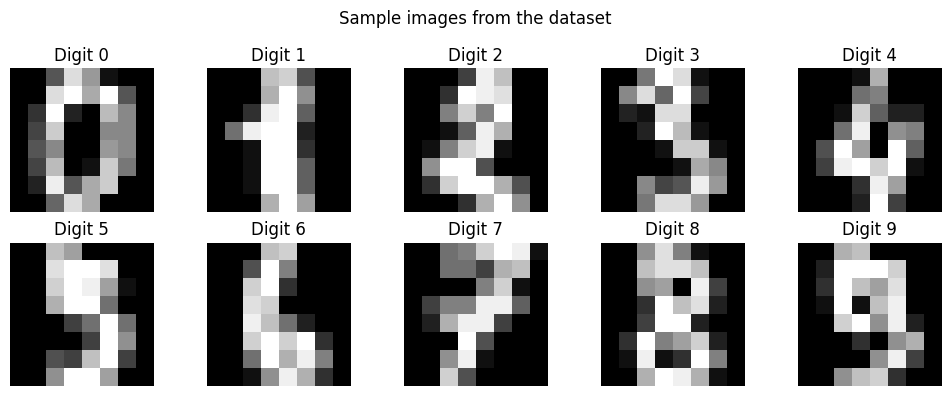

In [2]:
digits = load_digits()
images = digits.images.astype(np.float32) / 16.0
labels = digits.target.astype(np.int64)
class_names = [str(i) for i in range(10)]
print('Number of images:', len(images))
print('Original image dimensions:', images.shape[1:])
print('Classes:', class_names)
print('Class counts:', dict(zip(*np.unique(labels, return_counts=True))))
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, ax in enumerate(axes.flat):
    ix = np.flatnonzero(labels == digit)[0]
    ax.imshow(images[ix], cmap='gray', interpolation='nearest')
    ax.set_title(f'Digit {digit}'); ax.axis('off')
fig.suptitle('Sample images from the dataset'); plt.tight_layout(); plt.show()

## 3. Preprocessing and Data Loaders
Pixel values are normalized to 0–1. Data is split **70% training, 15% validation, 15% testing**, using stratification to retain class proportions. Images are resized with bilinear interpolation to 32 × 32. Training data alone is shuffled. No test images are used for training or hyperparameter selection.

In [3]:
from torch.nn import functional as F
x = torch.from_numpy(images).unsqueeze(1)
x = F.interpolate(x, size=(32, 32), mode='bilinear', align_corners=False)
y = torch.from_numpy(labels)
train_idx, other_idx = train_test_split(np.arange(len(labels)), test_size=0.30, random_state=SEED, stratify=labels)
val_idx, test_idx = train_test_split(other_idx, test_size=0.50, random_state=SEED, stratify=labels[other_idx])
BATCH_SIZE = 32
train_loader = DataLoader(TensorDataset(x[train_idx], y[train_idx]), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(x[val_idx], y[val_idx]), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(TensorDataset(x[test_idx], y[test_idx]), batch_size=BATCH_SIZE, shuffle=False)
print('Train:', len(train_idx), '| Validation:', len(val_idx), '| Test:', len(test_idx))
print('Image tensor shape:', tuple(x.shape[1:]), '| Batch size:', BATCH_SIZE)

Train: 1257 | Validation: 270 | Test: 270
Image tensor shape: (1, 32, 32) | Batch size: 32


## 4. Custom CNN Architecture
Two convolution blocks learn local features. **3 × 3 convolution filters** preserve spatial relationships, **ReLU** introduces nonlinearity, **max pooling** reduces feature map dimensions, and **dropout** reduces overfitting. The fully connected layer maps the learned features to ten output logits. CrossEntropyLoss internally applies the appropriate log-softmax operation, so the model returns raw logits.

In [4]:
class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(32 * 8 * 8, 64), nn.ReLU(),
            nn.Dropout(0.25), nn.Linear(64, 10)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

model = DigitCNN().to(device)
print(model)
print('Total trainable parameters:', sum(v.numel() for v in model.parameters() if v.requires_grad))
print('Output dimensions for one batch:', tuple(model(torch.zeros(2,1,32,32,device=device)).shape))

DigitCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)
Total trainable parameters: 136586
Output dimensions for one batch: (2, 10)


### Architecture summary
| Stage | Output size | Purpose |
|---|---|---|
| Input | 1 × 32 × 32 | Grayscale image |
| Conv 3×3 (16 filters), ReLU | 16 × 32 × 32 | Local feature extraction |
| MaxPool 2×2 | 16 × 16 × 16 | Downsampling |
| Conv 3×3 (32 filters), ReLU | 32 × 16 × 16 | Higher-level features |
| MaxPool 2×2 | 32 × 8 × 8 | Downsampling |
| Flatten | 2048 | Convert maps to features |
| Fully connected, ReLU | 64 | Classification features |
| Dropout 0.25 | 64 | Regularization |
| Fully connected | 10 | One score per digit |

**Hyperparameters:** batch size 32, learning rate 0.001, 18 epochs, Adam optimizer, cross-entropy loss. Adam adapts the update size for model parameters, and the moderate learning rate supports stable learning. A fixed random seed improves reproducibility. We choose the best epoch by validation accuracy.

## 5. Model Training and Validation
Each epoch performs forward propagation, loss calculation, backpropagation, and optimizer updates on training batches. The validation set is evaluated without gradient updates.

In [5]:
LEARNING_RATE = 0.001
EPOCHS = 18
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
history = {'train_loss':[], 'val_loss':[], 'train_acc':[], 'val_acc':[]}

def run_epoch(loader, training=False):
    model.train() if training else model.eval()
    loss_sum = correct = count = 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            if training: optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            if training:
                loss.backward()
                optimizer.step()
            loss_sum += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            count += len(yb)
    return loss_sum/count, correct/count

best_val = -1
best_state = None
for epoch in range(EPOCHS):
    tl, ta = run_epoch(train_loader, training=True)
    vl, va = run_epoch(val_loader)
    for k, v in zip(history, [tl, vl, ta, va]): history[k].append(v)
    if va > best_val:
        best_val = va
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    print(f'Epoch {epoch+1:02d}/{EPOCHS} | train loss {tl:.4f} | val loss {vl:.4f} | train acc {ta:.2%} | val acc {va:.2%}')
model.load_state_dict(best_state)
print(f'Best validation accuracy: {best_val:.2%}')

Epoch 01/18 | train loss 2.1200 | val loss 1.5203 | train acc 27.37% | val acc 62.22%


Epoch 02/18 | train loss 1.0382 | val loss 0.5067 | train acc 67.14% | val acc 85.56%


Epoch 03/18 | train loss 0.6130 | val loss 0.3922 | train acc 79.32% | val acc 88.15%


Epoch 04/18 | train loss 0.4877 | val loss 0.2851 | train acc 83.21% | val acc 91.48%


Epoch 05/18 | train loss 0.3997 | val loss 0.2366 | train acc 86.79% | val acc 92.22%


Epoch 06/18 | train loss 0.3798 | val loss 0.2142 | train acc 86.71% | val acc 92.96%
Epoch 07/18 | train loss 0.3175 | val loss 0.1765 | train acc 88.94% | val acc 95.19%


... (6 outputs left out)

Epoch 15/18 | train loss 0.1472 | val loss 0.1615 | train acc 94.75% | val acc 94.81%


Epoch 16/18 | train loss 0.1708 | val loss 0.1651 | train acc 93.48% | val acc 95.56%


Epoch 17/18 | train loss 0.1813 | val loss 0.1462 | train acc 93.95% | val acc 95.19%


Epoch 18/18 | train loss 0.1486 | val loss 0.1529 | train acc 95.07% | val acc 94.81%
Best validation accuracy: 96.30%


## 6. Training and Validation Curves
Loss shows the model's classification error, while accuracy shows the proportion of correctly predicted images. The gap between training and validation curves can indicate overfitting.

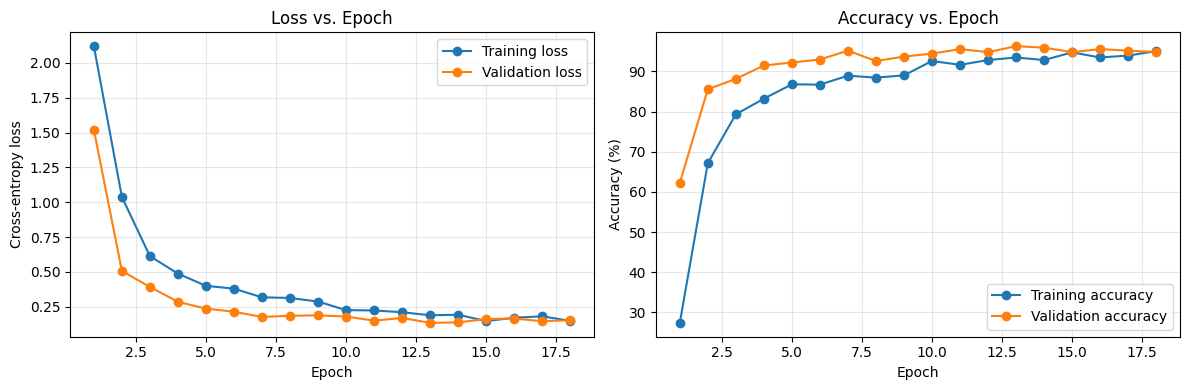

In [6]:
epochs = np.arange(1, len(history['train_loss'])+1)
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].plot(epochs,history['train_loss'],marker='o',label='Training loss')
axes[0].plot(epochs,history['val_loss'],marker='o',label='Validation loss')
axes[0].set(title='Loss vs. Epoch',xlabel='Epoch',ylabel='Cross-entropy loss');axes[0].legend();axes[0].grid(alpha=.3)
axes[1].plot(epochs,np.array(history['train_acc'])*100,marker='o',label='Training accuracy')
axes[1].plot(epochs,np.array(history['val_acc'])*100,marker='o',label='Validation accuracy')
axes[1].set(title='Accuracy vs. Epoch',xlabel='Epoch',ylabel='Accuracy (%)');axes[1].legend();axes[1].grid(alpha=.3)
plt.tight_layout();plt.savefig('training_curves.png',dpi=160,bbox_inches='tight');plt.show()

## 7. Test Evaluation
The held-out test set is evaluated once after selecting the model using validation accuracy. Besides test loss and accuracy, per-class precision, recall, F1-score, and a confusion matrix are reported.

Test loss: 0.0824
Test accuracy: 97.41%
Classification report:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        27
           1     0.8485    1.0000    0.9180        28
           2     1.0000    1.0000    1.0000        26
           3     1.0000    1.0000    1.0000        28
           4     1.0000    1.0000    1.0000        27
           5     1.0000    1.0000    1.0000        27
           6     1.0000    1.0000    1.0000        27
           7     0.9643    1.0000    0.9818        27
           8     0.9524    0.7692    0.8511        26
           9     1.0000    0.9630    0.9811        27

    accuracy                         0.9741       270
   macro avg     0.9765    0.9732    0.9732       270
weighted avg     0.9761    0.9741    0.9735       270



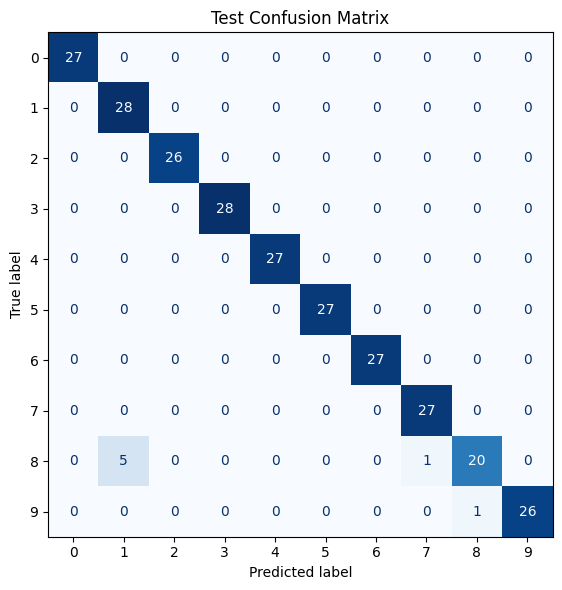

In [7]:
model.eval()
true_labels, pred_labels = [], []
test_loss_total = 0
with torch.no_grad():
    for xb,yb in test_loader:
        logits = model(xb.to(device))
        test_loss_total += criterion(logits,yb.to(device)).item()*len(yb)
        true_labels.extend(yb.numpy().tolist())
        pred_labels.extend(logits.argmax(1).cpu().numpy().tolist())
test_loss = test_loss_total/len(test_idx)
test_acc = np.mean(np.array(true_labels)==np.array(pred_labels))
report = classification_report(true_labels,pred_labels,target_names=class_names,digits=4,zero_division=0)
print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_acc:.2%}')
print('Classification report:'); print(report)
cm = confusion_matrix(true_labels,pred_labels)
fig,ax=plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay(cm,display_labels=class_names).plot(ax=ax,cmap='Blues',colorbar=False)
ax.set_title('Test Confusion Matrix')
plt.tight_layout();plt.savefig('confusion_matrix.png',dpi=160,bbox_inches='tight');plt.show()

## 8. Sample Predictions
The following examples show the model's predicted digit against the true digit on images from the held-out test set.

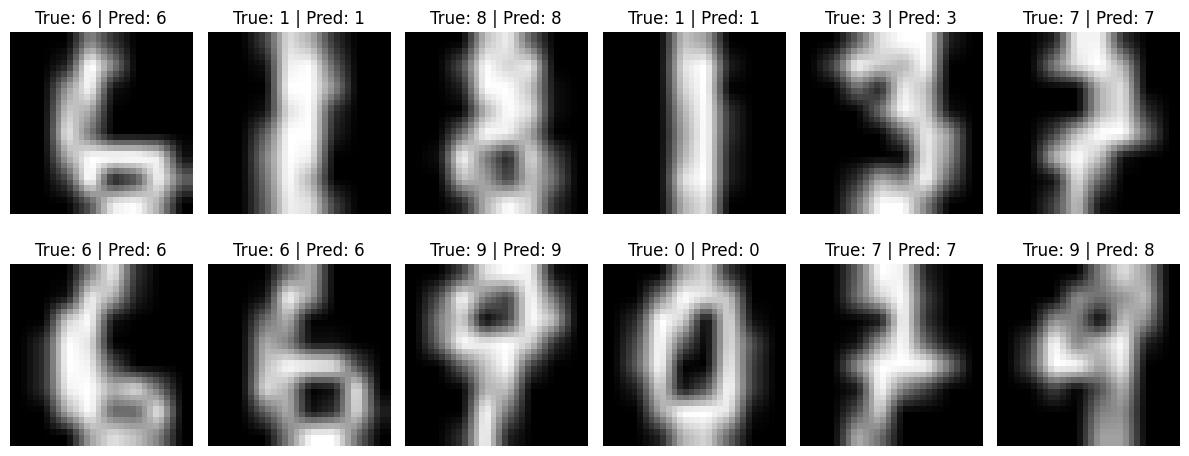

In [8]:
sample_ids = test_idx[:12]
model.eval()
with torch.no_grad():
    predictions = model(x[sample_ids].to(device)).argmax(1).cpu().numpy()
fig,axs=plt.subplots(2,6,figsize=(12,5))
for j,ax in enumerate(axs.flat):
    ax.imshow(x[sample_ids[j],0].numpy(),cmap='gray')
    truth=int(labels[sample_ids[j]]); pred=int(predictions[j])
    ax.set_title(f'True: {truth} | Pred: {pred}')
    ax.axis('off')
plt.tight_layout();plt.savefig('sample_predictions.png',dpi=160,bbox_inches='tight');plt.show()

## 9. Save and Reload Model
The saved `.pth` checkpoint contains the trained parameters, class names, image shape, and hyperparameters. Reloading confirms that the model can be used again without retraining.

In [9]:
MODEL_FILE = 'CNN_22-49447-3_weights.pth'
torch.save({'model_state_dict':model.state_dict(), 'classes':class_names,
            'image_shape':[1,32,32], 'learning_rate':LEARNING_RATE,
            'batch_size':BATCH_SIZE,'epochs':EPOCHS,'test_accuracy':float(test_acc)},MODEL_FILE)
reloaded = DigitCNN().to(device)
try:
    ckpt = torch.load(MODEL_FILE,map_location=device,weights_only=True)
except TypeError:
    ckpt = torch.load(MODEL_FILE,map_location=device)
reloaded.load_state_dict(ckpt['model_state_dict'])
reloaded.eval()
with torch.no_grad():
    check_equal = torch.equal(model(x[:3].to(device)).argmax(1),reloaded(x[:3].to(device)).argmax(1))
print('Model saved:',MODEL_FILE)
print('Model size (MB):',round(os.path.getsize(MODEL_FILE)/1024**2,2))
print('Reload prediction consistency:',check_equal)
with open('results.json','w') as f:
    json.dump({'student_id':'22-49447-3','test_accuracy':float(test_acc),
               'test_loss':float(test_loss),'best_validation_accuracy':float(best_val),
               'epochs':EPOCHS,'batch_size':BATCH_SIZE,'learning_rate':LEARNING_RATE},f,indent=2)
with open('classification_report.txt','w') as f: f.write(report)

Model saved: CNN_22-49447-3_weights.pth
Model size (MB): 0.53
Reload prediction consistency: True


## 10. Analysis and Discussion
This experiment trains a compact two-block CNN on grayscale handwritten digits. The training and validation curves illustrate changes in model performance across epochs. The confusion matrix highlights which digits the classifier confuses, and the classification report shows class-level performance.

The model was selected using the validation set rather than choosing hyperparameters based on the test set. The test evaluation therefore provides a separate estimate of how the model performs on unseen images. Performance can vary slightly with runtime and implementation versions, even with a fixed random seed.

In [10]:
print(f'Best validation accuracy: {best_val:.2%}')
print(f'Final test accuracy: {test_acc:.2%}')
print(f'Training accuracy at final epoch: {history["train_acc"][-1]:.2%}')
print(f'Validation accuracy at final epoch: {history["val_acc"][-1]:.2%}')
print('Review the confusion matrix to identify any visually similar digits that were confused.')

Best validation accuracy: 96.30%
Final test accuracy: 97.41%
Training accuracy at final epoch: 95.07%
Validation accuracy at final epoch: 94.81%
Review the confusion matrix to identify any visually similar digits that were confused.


## 11. Conclusion and Future Work
A custom CNN was designed, trained, and evaluated for ten-class handwritten digit recognition. Convolution layers learned image patterns, pooling reduced spatial dimensions, and fully connected layers produced class predictions. The experiment also demonstrated the importance of separate validation and test datasets.

Potential future improvements include experimenting with additional convolution layers, modest data augmentation, longer training, or comparing Adam with SGD on the same fixed data split.

**Dataset reference:** Dua, D. & Graff, C. (2019), UCI Machine Learning Repository; accessible through scikit-learn's `load_digits`.